# Notebook 8 — FCC-ee: install 6D beam–beam lenses

Load the original `fccee_z.json` lattice and install one `xfields.BeamBeamBiGaussian3D` element at each of the four interaction points: `ipa`, `ipd`, `ipg`, and `ipj`.

## Your tasks

1. Calculate the nominal optics and inspect the IP beta functions.
2. Define an opposing electron bunch using published FCC-ee Z-pole parameters.
3. Slice the opposing bunch longitudinally and construct its transverse covariance matrix at each IP.
4. Install the four lenses and connect their strengths to a common knob.
5. Switch the beam–beam interaction on and compare the tunes and beta functions.
6. Add illustrative apertures and compare particle losses with the crab sextupoles on and off.

Use a **weak–strong model**: track the positron beam through a prescribed electron bunch whose distribution stays fixed. The 6D lenses include the crossing angle, hourglass effect, and longitudinal kicks. Synchrotron radiation and beamstrahlung emission are off for this exercise.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt
import xfields as xf
from xfields.config_tools.beambeam_config_tools.config_tools import constant_charge_slicing_gaussian

### Published beam parameters

Use the Z-pole parameters in D. Gibellieri's [FCC Week 2025 presentation, slide 4](https://indico.cern.ch/event/1408515/contributions/6515086/attachments/3070936/5433965/FCCweek_Collimators_Impedance_Gibellieri_250520.pdf):

| Parameter | Value |
|---|---:|
| Beam energy | 45.6 GeV |
| Particles per opposing bunch | $2.18\times10^{11}$ |
| Horizontal geometric emittance | 0.71 nm |
| Vertical geometric emittance in collision | 2.1 pm |
| RMS bunch length, SR only / in collision | 5.15 / 15.2 mm |

The **full horizontal crossing angle is 30 mrad**, as specified in [Boscolo et al., *Status of the FCC-ee interaction region design* (2025), section 2](https://doi.org/10.1140/epjti/s40485-025-00117-3). Xfields takes the **half angle**, `phi = 15e-3`.

Here use the colliding bunch length, 15.2 mm, as a fixed input even though beamstrahlung emission is disabled. This does not calculate the colliding equilibrium self-consistently.

The published parameter set has $\beta_x^*/\beta_y^*=110/0.7$ mm. Our supplied lattice has **90/0.8 mm**; use its own beta functions to determine the opposing beam sizes. Keep the lattice's original optics and RF settings. This is a teaching model using published bunch parameters, rather than a reproduction of that complete design point.

In [2]:
bunch_population = 2.18e11
gemitt_x = 0.71e-9  # m, geometric emittance
gemitt_y = 2.1e-12  # m, geometric emittance
sigma_z = 15.2e-3   # m, colliding bunch length
crossing_angle = 30e-3  # rad, full angle
n_slices = 201

### Load the original lattice

Start from the JSON again, so this notebook is independent of the beta-star changes in notebook 7. Use 6D Twiss with the existing RF cavities and radiation off.

In [3]:
env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)
ips = ['ipa', 'ipd', 'ipg', 'ipj']

beta_gamma = line.particle_ref.beta0[0] * line.particle_ref.gamma0[0]
twiss_kwargs = dict(
    method='6d', chrom=False,
    nemitt_x=gemitt_x * beta_gamma,
    nemitt_y=gemitt_y * beta_gamma,
    step_W_sigma=0.001,
    steps_R_matrix=dict(
        dx=1e-8, dpx=1e-9, dy=1e-10, dpy=1e-10,
        dzeta=1e-4, ddelta=1e-5,
    ),
)
tw0 = line.twiss(**twiss_kwargs)
print(f'Energy: {line.particle_ref.energy0[0] / 1e9:.2f} GeV')
print(f'Tracked-beam charge: {line.particle_ref.q0:+g} e')
tw0.rows[ips].cols['s betx bety alfx alfy dx dy']

Loading line from dict:   0%|          | 0/19024 [00:00<?, ?it/s]

Energy: 45.60 GeV
Tracked-beam charge: +1 e


TwissTable: 4 rows, 8 cols
name             s          betx          bety          alfx          alfy            dx ...
ipa              0     0.0900007        0.0008   8.82784e-10   1.04238e-08   6.93308e-08
ipd        22665.1     0.0900007        0.0008   5.84611e-09  -1.80089e-08  -4.44384e-07
ipg        45330.1     0.0900007        0.0008   1.84767e-08  -3.79341e-08   3.31659e-07
ipj        67995.2     0.0900007        0.0008   2.84838e-08  -9.21253e-08  -2.25077e-07

### Describe the opposing beam

Only the positron ring is supplied. Assume the opposing electron beam has the same IP optics viewed in the opposite direction. `reverse()` expresses the nominal Twiss in that direction; use it to construct the transverse covariances, including position–momentum correlations. The emittances above specify the strong beam and stay fixed when the weak-beam optics changes.

At an uncoupled waist, $\Sigma_{11}=\epsilon_x\beta_x$, $\Sigma_{22}=\epsilon_x/\beta_x$, and similarly in the vertical plane. The `Sigma` inputs are **variances and covariances**, not RMS sizes. Longitudinal slicing allows the lens to propagate these moments from the IP to each collision point.

In [4]:
tw_other = tw0.reverse()
sigmas = tw_other.get_beam_covariance(gemitt_x=gemitt_x, gemitt_y=gemitt_y)

print(f'{"IP":<5} {"sigma_x [um]":>15} {"sigma_y [nm]":>15}')
for ip in ips:
    print(f'{ip:<5} {np.sqrt(sigmas["Sigma11", ip]) * 1e6:15.3f} '
          f'{np.sqrt(sigmas["Sigma33", ip]) * 1e9:15.3f}')

IP       sigma_x [um]    sigma_y [nm]
ipa             7.994          40.988
ipd             7.994          40.988
ipg             7.994          40.988
ipj             7.994          40.988


### Slice the opposing bunch

Use `constant_charge_slicing_gaussian`, the helper used by the environment beam–beam installation workflow. It splits the Gaussian bunch into slices with equal population and returns their charge centroids and boundaries. The slices are narrower near the bunch centre.

Each lens represents the **whole opposing bunch**: its slice populations sum to `bunch_population`. Reverse the returned arrays to put the slices in decreasing zeta, as required by `BeamBeamBiGaussian3D`. The large crossing angle makes slice resolution important; repeat with more slices when checking convergence.

Population summed over slices: 2.180e+11


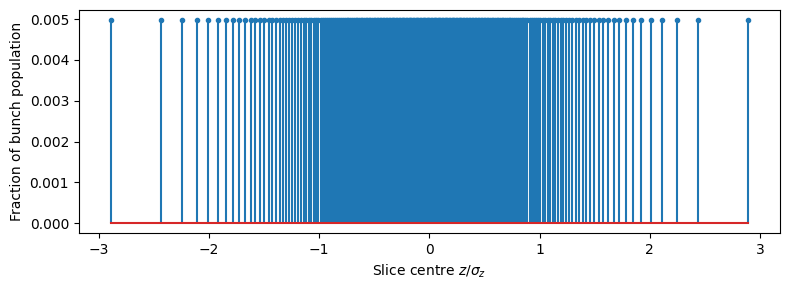

In [5]:
z_centroids, z_cuts, num_particles_per_slice = constant_charge_slicing_gaussian(
    N_part_tot=bunch_population, sigmaz=sigma_z, N_slices=n_slices,
)
z_centroids = z_centroids[::-1]
num_particles_per_slice = num_particles_per_slice[::-1]
print(f'Population summed over slices: {np.sum(num_particles_per_slice):.3e}')

plt.figure(figsize=(8, 3))
plt.stem(z_centroids / sigma_z, num_particles_per_slice / bunch_population, markerfmt='.')
plt.xlabel(r'Slice centre $z/\sigma_z$')
plt.ylabel('Fraction of bunch population')
plt.tight_layout()

### Install one lens at each IP

The opposing beam has the opposite charge, so the interaction is focusing. Use `alpha=0` for a horizontal crossing plane and the same local crossing convention at all four IPs. Keep each IP marker and insert its lens at the same longitudinal position.

`on_bb=0` switches off all four lenses; `on_bb=1` gives the full bunch population. The fixed covariance inputs are evaluated before the lenses are enabled.

In [6]:
line.discard_tracker()
env['on_bb'] = 0
bb_names = []
for ip in ips:
    bb_name = f'bb_{ip}'
    bb = xf.BeamBeamBiGaussian3D(
        phi=crossing_angle / 2,
        alpha=0,
        other_beam_q0=-line.particle_ref.q0,
        slices_other_beam_num_particles=num_particles_per_slice,
        slices_other_beam_zeta_center=z_centroids,
        slices_other_beam_Sigma_11=sigmas['Sigma11', ip],
        slices_other_beam_Sigma_12=sigmas['Sigma12', ip],
        slices_other_beam_Sigma_22=sigmas['Sigma22', ip],
        slices_other_beam_Sigma_33=sigmas['Sigma33', ip],
        slices_other_beam_Sigma_34=sigmas['Sigma34', ip],
        slices_other_beam_Sigma_44=sigmas['Sigma44', ip],
        flag_beamstrahlung=0,
    )
    line.insert(bb_name, bb, at=ip, with_progress=False)
    env.ref[bb_name].scale_strength = env.ref['on_bb']
    bb_names.append(bb_name)
line.build_tracker()

In [7]:
tt = line.get_table()
tt.rows[tt.element_type == 'BeamBeamBiGaussian3D'].cols['s element_type']

LineTable: 4 rows, 3 cols
name               s element_type        
bb_ipa             0 BeamBeamBiGaussian3D
bb_ipd       22665.1 BeamBeamBiGaussian3D
bb_ipg       45330.1 BeamBeamBiGaussian3D
bb_ipj       67995.2 BeamBeamBiGaussian3D

### Compare optics with the interaction off and on

The Twiss calculation uses small finite-difference steps (`steps_R_matrix`) to find the linear one-turn map, and the beam emittances to set the probes used to propagate the optical functions. This matters for the nanometre-scale vertical beam: large probes sample nonlinear kicks instead of the core focusing.

These are the incoherent small-amplitude tunes of the weak beam in the fixed strong-beam field. The full-strength tune change includes the change in beta functions; it is not simply four times a first-order beam–beam parameter.

In [8]:
env['on_bb'] = 0
tw_off = line.twiss(**twiss_kwargs)
env['on_bb'] = 1
tw_bb = line.twiss(**twiss_kwargs)

print(f'Beam–beam off: Qx = {tw_off.qx:.6f}, Qy = {tw_off.qy:.6f}')
print(f'Beam–beam on:  Qx = {tw_bb.qx:.6f}, Qy = {tw_bb.qy:.6f}')
print(f'Tune changes:  dQx = {tw_bb.qx - tw_off.qx:.6f}, '
      f'dQy = {tw_bb.qy - tw_off.qy:.6f}')
tw_bb.rows[ips].cols['betx bety alfx alfy']

Beam–beam off: Qx = 166.160000, Qy = 162.200000
Beam–beam on:  Qx = 166.167613, Qy = 162.477107
Tune changes:  dQx = 0.007613, dQy = 0.277107


TwissTable: 4 rows, 5 cols
name          betx          bety          alfx          alfy
ipa      0.0859544   0.000485999     0.0112629      0.167551
ipd      0.0859569    0.00048564     0.0112803      0.166798
ipg      0.0859566   0.000485959      0.011295      0.166283
ipj       0.085953   0.000486273     0.0112908      0.167003

### Crab sextupoles and particle losses

The dedicated crab-waist sextupoles are controlled by `cs_frac`; their nominal setting in this lattice is **0.55**. Setting it to zero switches off these magnets while leaving the other sextupole families unchanged.

Scan **10 momentum offsets from −1% to +1%** and **10 transverse amplitudes from 0.5σ to 5σ**. Use the same normalized amplitude in both planes, zero normalized transverse momenta and `zeta=0`. Track the 100 particles for **200 turns** with beam–beam enabled.

On a copy of the ring, add identical loss boundaries in both cases near the vertical beta maximum downstream of each IP. Their horizontal and vertical half-apertures are 8 and 6 times the RMS beam sizes calculated from the original optics without beam–beam. These are illustrative apertures, not FCC-ee hardware specifications. Radiation and beamstrahlung remain off.

In [9]:
line_loss = line.copy()
line_loss.vars['on_bb'] = 1
crab_nominal = line_loss.vars['cs_frac']._value

for ip in ips:
    s_ip = tw0['s', ip]
    indices = np.flatnonzero((tw0.s > s_ip) & (tw0.s < s_ip + 20))
    i_ap = indices[np.argmax(tw0.bety[indices])]
    half_x = 8 * np.sqrt(gemitt_x * tw0.betx[i_ap])
    half_y = 6 * np.sqrt(gemitt_y * tw0.bety[i_ap])
    line_loss.insert(
        f'loss_ap_{ip}',
        xt.LimitRect(min_x=-half_x, max_x=half_x,
                     min_y=-half_y, max_y=half_y),
        at=float(tw0.s[i_ap]), with_progress=False,
    )
    print(f'{ip}: half-apertures {half_x * 1e3:.2f} mm / {half_y * 1e3:.2f} mm')
line_loss.build_tracker()

ipa: half-apertures 4.23 mm / 0.99 mm


ipd: half-apertures 4.23 mm / 0.99 mm


ipg: half-apertures 4.23 mm / 0.99 mm


ipj: half-apertures 4.23 mm / 0.99 mm


### Launch an amplitude–momentum grid

Use `np.meshgrid` to combine the momentum offsets and transverse amplitudes, then flatten the arrays for `line_loss.build_particles`. At each point, launch with $x_n=y_n=A$ and $p_{x,n}=p_{y,n}=0$. Supply the beam–beam-on closed orbit and normal-form matrix so both runs use the same transverse normalization. All particles start at `zeta=0`; their momentum offsets subsequently evolve under the RF and 6D beam–beam kicks.

In [10]:
n_turns = 200
delta_values = np.linspace(-1e-2, 1e-2, 10)
amplitude_values = np.linspace(0.5, 5, 10)
delta_grid, amplitude_grid = np.meshgrid(delta_values, amplitude_values)
n_particles = delta_grid.size

particles_initial = line_loss.build_particles(
    x_norm=amplitude_grid.ravel(), px_norm=0,
    y_norm=amplitude_grid.ravel(), py_norm=0,
    zeta=0, delta=delta_grid.ravel(),
    nemitt_x=gemitt_x * beta_gamma,
    nemitt_y=gemitt_y * beta_gamma,
    particle_on_co=tw_bb.particle_on_co,
    W_matrix=tw_bb.W_matrix[0],
)

### Track with crab sextupoles on and off

Use copies of the same initial particles, keeping the apertures and beam–beam settings fixed. Record the loss turn and compare survival across the amplitude–momentum grid.

In [11]:
import time

tracked_particles = {}
for label, crab_fraction in [('Crab on', crab_nominal), ('Crab off', 0)]:
    line_loss.vars['cs_frac'] = crab_fraction
    particles = particles_initial.copy()
    start_time = time.perf_counter()
    line_loss.track(particles, num_turns=n_turns)
    elapsed = time.perf_counter() - start_time
    tracked_particles[label] = particles
    n_lost = np.count_nonzero(particles.state <= 0)
    print(f'{label}: {n_lost}/{n_particles} lost after {n_turns} turns '
          f'({elapsed:.1f} s tracking)')

line_loss.vars['cs_frac'] = crab_nominal

Crab on: 17/100 lost after 200 turns (57.2 s tracking)


Crab off: 48/100 lost after 200 turns (42.7 s tracking)


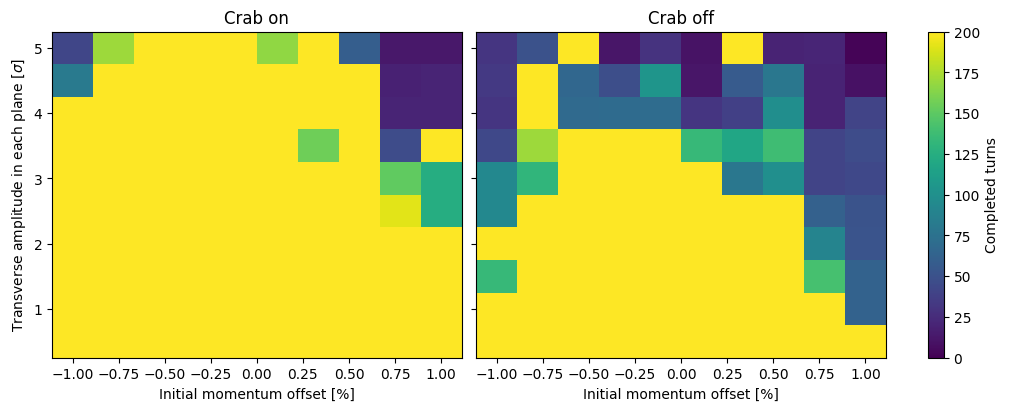

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         layout='constrained')
for ax, (label, particles) in zip(axes, tracked_particles.items()):
    order = np.argsort(particles.particle_id)
    turns = particles.at_turn[order].reshape(delta_grid.shape)
    mesh = ax.pcolormesh(100 * delta_values, amplitude_values, turns,
                         shading='nearest', cmap='viridis', vmin=0, vmax=n_turns)
    ax.set_title(label)
    ax.set_xlabel('Initial momentum offset [%]')
axes[0].set_ylabel(r'Transverse amplitude in each plane [$\sigma$]')
fig.colorbar(mesh, ax=axes, label='Completed turns')

The colour shows how many turns each particle completed; 200 means it survived the full simulation. Both panels use the same colour scale. Sorting by particle ID restores the launch-grid order after tracking has rearranged lost particles.

This is a coarse amplitude–momentum survival map at one transverse phase and with equal normalized amplitudes in both planes. It illustrates the effect of the crab sextupoles; it is not a full momentum-acceptance boundary or a beam-lifetime estimate.

Try changing the momentum range, amplitude range, or number of turns. Keep the initial particles and apertures identical when comparing the crab settings.